## Text Processing Fundamentals

In [3]:
# Import nltk
import nltk
# Download the punkt_tab package 
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /home/omer-
[nltk_data]     yaslitas/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [4]:
text = """
The stock market saw a significant dip today. Experts believe the downturn may continue.
However, many investors are optimistic about future growth.
"""

# Tokenize the text into sentences
sentences = nltk.sent_tokenize(text)
print(sentences)

['\nThe stock market saw a significant dip today.', 'Experts believe the downturn may continue.', 'However, many investors are optimistic about future growth.']


In [6]:
# Tokenize the first sentence into words
words = nltk.word_tokenize(sentences[0])
print(words)

['The', 'stock', 'market', 'saw', 'a', 'significant', 'dip', 'today', '.']


### Stop words and punctuation

In [8]:
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

feedback = "I reached out to support and got a helpful response within minutes!!! Very #impressed"

# Tokenize the text
tokens = word_tokenize(feedback)

# Get the list of English stop words
stop_words = stopwords.words('english')

# Remove stop words 
filtered_tokens = [word for word in tokens if word.lower() not in stop_words]

print(filtered_tokens)

['reached', 'support', 'got', 'helpful', 'response', 'within', 'minutes', '!', '!', '!', '#', 'impressed']


In [9]:
import string

filtered_tokens = ['reached', 'support', 'got', 'helpful', 'response', 'within', 'minutes', '!', '!', '!', '#', 'impressed']

# Remove punctuation
clean_tokens = [word for word in filtered_tokens if word not in string.punctuation]

print(clean_tokens)

['reached', 'support', 'got', 'helpful', 'response', 'within', 'minutes', 'impressed']


### Text Normalization

In [10]:
review = "I have been FLYING a lot lately and the Flights just keep getting DELAYED. Honestly, traveling for WORK gets exhausting with endless delays, but every trip teaches you something new!"

# Lowercase the review
lower_text = review.lower()

# Tokenize the lower_text into words
tokens = word_tokenize(lower_text)

# Remove stop words and punctuation
clean_tokens = [word for word in tokens if word not in stop_words and word not in string.punctuation]

print(clean_tokens)

['flying', 'lot', 'lately', 'flights', 'keep', 'getting', 'delayed', 'honestly', 'traveling', 'work', 'gets', 'exhausting', 'endless', 'delays', 'every', 'trip', 'teaches', 'something', 'new']


In [11]:
from nltk.stem import PorterStemmer

# Stemming
clean_tokens = ['flying', 'lot', 'lately', 'flights', 'keep', 'getting', 'delayed', 'honestly', 'traveling', 'work', 'gets', 'exhausting', 'endless', 'delays', 'every', 'travel', 'teaches', 'something', 'new']

# Create stemmer
stemmer = PorterStemmer()

# Stem each token
stemmed_tokens = [stemmer.stem(token) for token in clean_tokens]

print(stemmed_tokens)

['fli', 'lot', 'late', 'flight', 'keep', 'get', 'delay', 'honestli', 'travel', 'work', 'get', 'exhaust', 'endless', 'delay', 'everi', 'travel', 'teach', 'someth', 'new']


In [14]:
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to /home/omer-
[nltk_data]     yaslitas/nltk_data...


True

In [15]:
from nltk.stem import WordNetLemmatizer

# Lemmatization
clean_tokens = ['flying', 'lot', 'lately', 'flights', 'keep', 'getting', 'delayed', 'honestly', 'traveling', 'work', 'gets', 'exhausting', 'endless', 'delays', 'every', 'travel', 'teaches', 'something', 'new']

# Create lemmatizer
lemmatizer = WordNetLemmatizer()

# Lemmatize each token
lemmatized_tokens = [lemmatizer.lemmatize(token) for token in clean_tokens]

print(lemmatized_tokens)

['flying', 'lot', 'lately', 'flight', 'keep', 'getting', 'delayed', 'honestly', 'traveling', 'work', 'get', 'exhausting', 'endless', 'delay', 'every', 'travel', 'teach', 'something', 'new']


## Feature Extraction from Text

In [32]:
def preprocess(text):
    text = text.lower()
    tokens = word_tokenize(text)
    tokens = [word for word in tokens if word not in string.punctuation]
    return " ".join(tokens)

### Bag of Words (BoW) Representation

In [18]:
from sklearn.feature_extraction.text import CountVectorizer

reviews = [
    "The product is fantastic! It works like a charm.",
    "I hated the product. It broke after one use.",
    "Product was okay, not the best, but fine overall."
]
# Preprocess the reviews
cleaned_reviews = [preprocess(review) for review in reviews]

vectorizer = CountVectorizer()
# Fit the vectorizer
vectorizer.fit(cleaned_reviews)
# Print the vocabulary 
print(vectorizer.get_feature_names_out())

['after' 'best' 'broke' 'but' 'charm' 'fantastic' 'fine' 'hated' 'is' 'it'
 'like' 'not' 'okay' 'one' 'overall' 'product' 'the' 'use' 'was' 'works']


In [19]:
# Transform the reviews
bow_matrix = vectorizer.transform(cleaned_reviews)

# Print the BoW representation
print(bow_matrix.toarray())

[[0 0 0 0 1 1 0 0 1 1 1 0 0 0 0 1 1 0 0 1]
 [1 0 1 0 0 0 0 1 0 1 0 0 0 1 0 1 1 1 0 0]
 [0 1 0 1 0 0 1 0 0 0 0 1 1 0 1 1 1 0 1 0]]


In [20]:
def get_top_ten(words, word_counts):
    top_n = 10

    word_count_pairs = list(zip(words, word_counts))
    word_count_pairs_sorted = sorted(word_count_pairs, key=lambda x: x[1], reverse=True)

    top_n_pairs = word_count_pairs_sorted[:top_n]
    top_words = [word for word, count in top_n_pairs]
    top_counts = [count for word, count in top_n_pairs]

    return top_words, top_counts

In [24]:
import pandas as pd
product_reviews = pd.read_csv('data/product_reviews.csv')
product_reviews = product_reviews['Text']

In [25]:
import numpy as np

cleaned_reviews = [preprocess(review) for review in product_reviews]
X = vectorizer.fit_transform(cleaned_reviews)

# Get word counts
word_counts = np.sum(X.toarray(), axis=0)
# Get words
words = vectorizer.get_feature_names_out()

top_words_with_stopwords, top_counts_with_stopwords = get_top_ten(words, word_counts)
print(top_words_with_stopwords, top_counts_with_stopwords)

['the', 'and', 'to', 'it', 'of', 'is', 'br', 'this', 'in', 'for'] [np.int64(3161), np.int64(2123), np.int64(1522), np.int64(1504), np.int64(1335), np.int64(1169), np.int64(1102), np.int64(978), np.int64(895), np.int64(871)]


In [ ]:
# Modify the function to remove stop words 

stop_words.append('br')

def preprocess_extended(text):
    text = text.lower()
    tokens = word_tokenize(text)
    tokens = [word for word in tokens if word not in string.punctuation]
    tokens = [word for word in tokens if word not in stop_words]
    return " ".join(tokens)

cleaned_reviews = [preprocess_extended(review) for review in product_reviews]
X = vectorizer.fit_transform(cleaned_reviews)

# Get word counts
word_counts = np.sum(X.toarray(), axis=0)
# Get words
words = vectorizer.get_feature_names_out()

top_words_without_stopwords, top_counts_without_stopwords = get_top_ten(words, word_counts)
print(top_words_without_stopwords, top_counts_without_stopwords)

['chips', 'like', 'good', 'taste', 'great', 'flavor', 'one', 'product', 'food', 'love'] [np.int64(562), np.int64(415), np.int64(323), np.int64(289), np.int64(286), np.int64(280), np.int64(271), np.int64(238), np.int64(219), np.int64(218)]


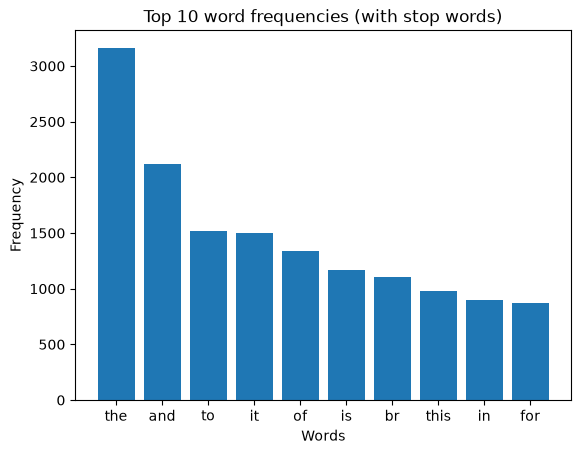

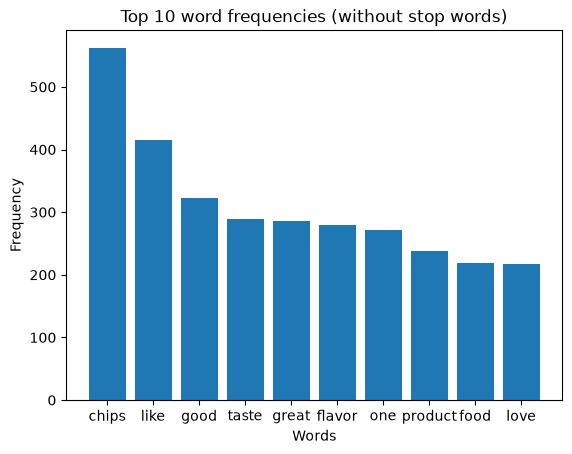

In [29]:
import matplotlib.pyplot as plt
# Plot the frequencies with stop words
plt.bar(top_words_with_stopwords, top_counts_with_stopwords)
plt.title("Top 10 word frequencies (with stop words)")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.show()

# Plot the frequencies without stop words
plt.figure()
plt.bar(top_words_without_stopwords, top_counts_without_stopwords)
plt.title("Top 10 word frequencies (without stop words)")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.show()

### TF-IDF Vectorization

In [33]:
from sklearn.feature_extraction.text import TfidfVectorizer

reviews = ["The smart speaker is incredible. Clear sound and fast responses!",
            "I am disappointed with the smart bulb. It stopped working in a week.",
            "The thermostat is okay. Not too smart, but functional."]
cleaned_reviews = [preprocess(review) for review in reviews]

# Initialize the vectorizer
vectorizer = TfidfVectorizer()
# Transform the cleaned reviews
tfidf_matrix = vectorizer.fit_transform(cleaned_reviews)
# Create a DataFrame for TF-IDF
df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=vectorizer.get_feature_names_out()
)
df.head()

,am,and,bulb,but,clear,disappointed,fast,functional,in,incredible,...,smart,sound,speaker,stopped,the,thermostat,too,week,with,working
0,0.000000,0.347607,0.000000,0.000000,0.347607,0.000000,0.347607,0.000000,0.000000,0.347607,...,0.205302,0.347607,0.347607,0.000000,0.205302,0.000000,0.000000,0.000000,0.000000,0.000000
1,0.321119,0.000000,0.321119,0.000000,0.000000,0.321119,0.000000,0.000000,0.321119,0.000000,...,0.189658,0.000000,0.000000,0.321119,0.189658,0.000000,0.000000,0.321119,0.321119,0.321119
2,0.000000,0.000000,0.000000,0.370725,0.000000,0.000000,0.000000,0.370725,0.000000,0.000000,...,0.218956,0.000000,0.000000,0.000000,0.218956,0.370725,0.370725,0.000000,0.000000,0.000000


In [35]:
cleaned_reviews = [preprocess(review) for review in reviews]

vectorizer = CountVectorizer()
# Fit the vectorizer
vectorizer.fit(cleaned_reviews)

bow_matrix = vectorizer.transform(cleaned_reviews)

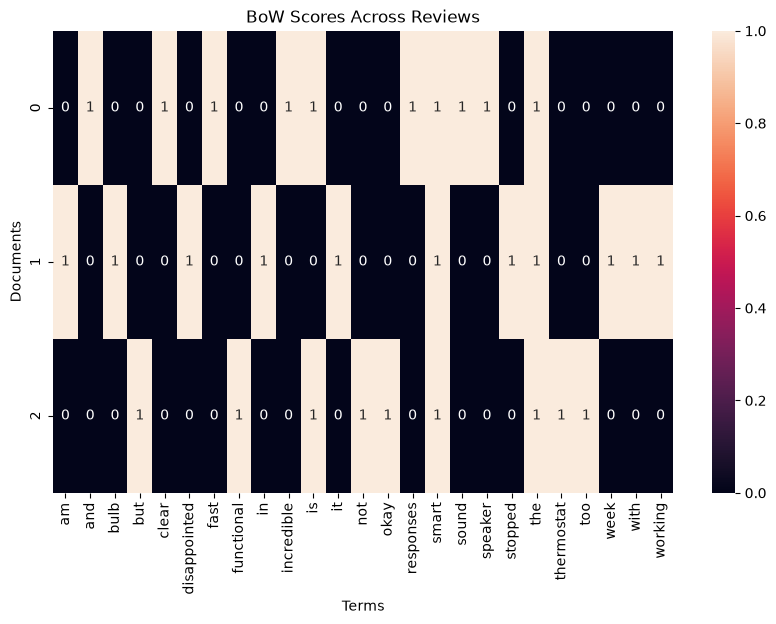

In [37]:
import seaborn as sns

# Convert BoW matrix to a DataFrame
df_bow = pd.DataFrame(
    bow_matrix.toarray(),
    columns=vectorizer.get_feature_names_out()
)

# Plot the heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(df_bow, annot=True)
plt.title("BoW Scores Across Reviews")
plt.xlabel("Terms") 
plt.xticks(rotation=90)
plt.ylabel("Documents")
plt.show()

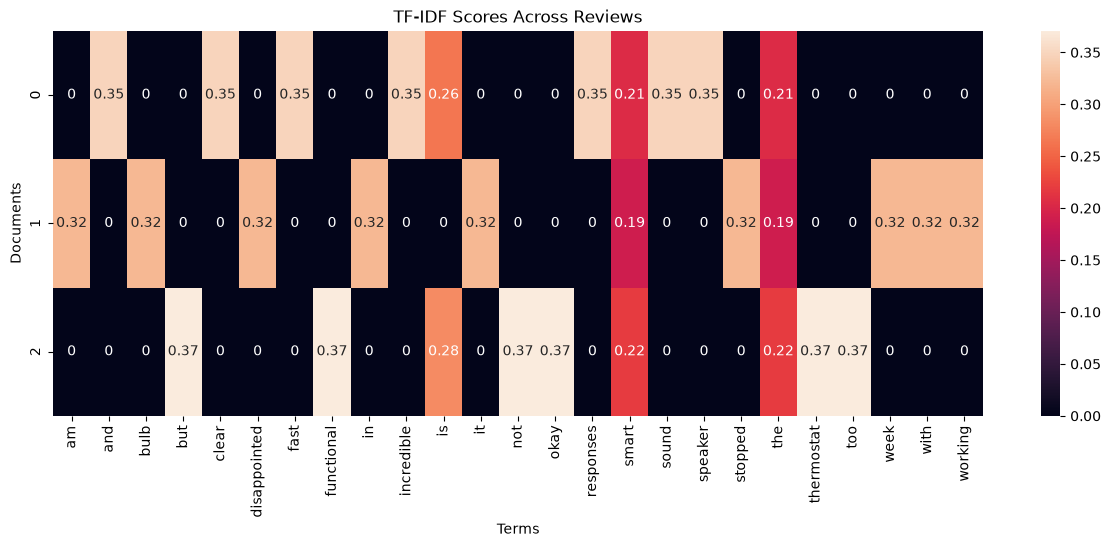

In [42]:
# Convert TF-IDF matrix to a DataFrame
df_tfidf = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=vectorizer.get_feature_names_out()
)

# Plot the heatmap
plt.figure(figsize=(len(df_tfidf.columns) * 0.6, 5))
sns.heatmap(df_tfidf, annot=True)
plt.title("TF-IDF Scores Across Reviews")
plt.xlabel("Terms")
plt.xticks(rotation=90)
plt.ylabel("Documents")
plt.show()

### Embeddings

In [1]:
import gensim.downloader as api
model_glove_wiki = api.load("glove-wiki-gigaword-50")

[==================================================] 100.0% 66.0/66.0MB downloaded


In [3]:
# Compute similarity between "king" and "queen"
similarity_score = model_glove_wiki.similarity("king", "queen")

print(similarity_score)

# Get top 10 most similar words to "computer    "
similar_words = model_glove_wiki.most_similar("computer", topn=10)

print(similar_words)

0.78390425
[('computers', 0.9165045022964478), ('software', 0.8814992904663086), ('technology', 0.852556049823761), ('electronic', 0.812586784362793), ('internet', 0.8060455322265625), ('computing', 0.802603542804718), ('devices', 0.8016185760498047), ('digital', 0.7991793751716614), ('applications', 0.7912740707397461), ('pc', 0.7883159518241882)]


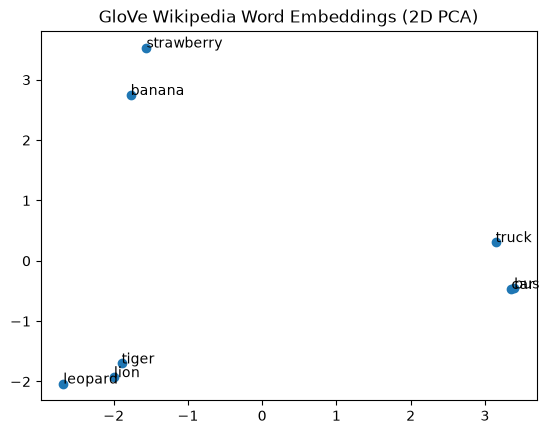

In [5]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

words = ["lion", "tiger", "leopard", "banana", "strawberry", "truck", "car", "bus"]

# Extract word embeddings
word_vectors = [model_glove_wiki[word] for word in words]

# Reduce dimensions with PCA
pca = PCA(n_components=2)
word_vectors_2d = pca.fit_transform(word_vectors)

plt.scatter(word_vectors_2d[:, 0], word_vectors_2d[:, 1])
for word, (x, y) in zip(words, word_vectors_2d):
    plt.annotate(word, (x, y))
plt.title("GloVe Wikipedia Word Embeddings (2D PCA)")
plt.show()

In [6]:
model_glove_twitter = api.load("glove-twitter-25")

[==================================================] 100.0% 104.8/104.8MB downloaded


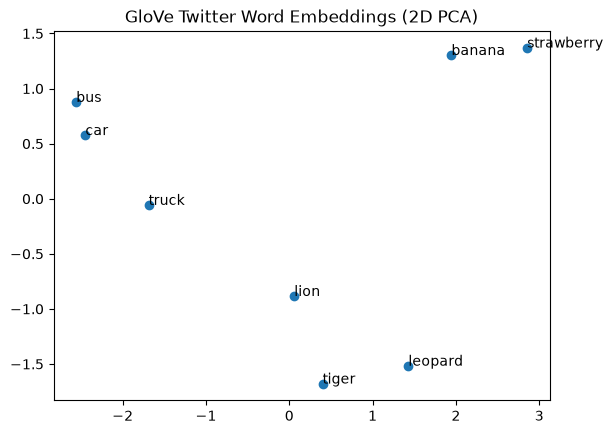

In [7]:
words = ["lion", "tiger", "leopard", "banana", "strawberry", "truck", "car", "bus"]

# Change the embedding model
word_vectors = [model_glove_twitter[word] for word in words]

# Reduce dimensions with PCA
pca = PCA(n_components=2)
word_vectors_2d = pca.fit_transform(word_vectors)

plt.scatter(word_vectors_2d[:, 0], word_vectors_2d[:, 1])
for word, (x, y) in zip(words, word_vectors_2d):
    plt.annotate(word, (x, y))
plt.title("GloVe Twitter Word Embeddings (2D PCA)")
plt.show()

## Text Classification with Hugging Face

### Sentiment Analysis

In [1]:
import torch
from transformers import pipeline

# Define the sentiment analysis pipeline
classifier = pipeline(task="sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english")

review_text = "The new update made the app much faster and easier to use!"

# Get sentiment prediction
result = classifier(review_text)

print(result)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9979780316352844}]


In [2]:
from transformers import pipeline

classifier = pipeline(task="sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english")

review_batch = [
    "Absolutely love the new design!",
    "The app crashes every time I open it.",
    "Customer support was helpful and quick.",
    "Too many ads make it unusable.",
    "Everything works fine, but it’s a bit slow."
]

# Classify sentiments
results = classifier(review_batch)
print(results)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'POSITIVE', 'score': 0.9998812675476074}, {'label': 'NEGATIVE', 'score': 0.9995560050010681}, {'label': 'POSITIVE', 'score': 0.9994823932647705}, {'label': 'NEGATIVE', 'score': 0.9997507929801941}, {'label': 'NEGATIVE', 'score': 0.9972020387649536}]


In [3]:
texts = ["I can't believe how great this app is, it’s honestly a game-changer!",
 'It’s not as bad as I expected, but still not great.',
 'The update did fix a lot of issues, so I’m glad they listened to feedback.',
 'It’s just another buggy version with more problems than before.',
 "I'm amazed by how quickly it works now, truly impressed.",
 "Oh look, the app works for once. Not sure if it's a fluke or progress.",
 "The new design is a pleasant surprise — I didn't expect it to be this good.",
 'The app keeps freezing when I need it most. Terrible experience.',
 'I didn’t think it was possible, but this update made things even worse.',
 'Wow, finally an update that makes sense. So happy about this!',
 'At least the app doesn’t crash every five minutes now. That’s something.',
 'I’ve never been so impressed by an app’s performance. Outstanding!',
 'I’m sure it works for some people, but not for me. A lot of problems.',
 'It’s almost like the developers actually care now. Big improvement!',
 'The app is still the same: slow, frustrating, and useless.',
 'The new features are cool, but the app is still very glitchy.',
 'I wish I had known about this app sooner, it really does make a difference.',
 'I regret wasting my time on this app. I’ve had enough.',
 'I’m so happy they fixed that bug, I didn’t realize how much it bothered me.',
 'The app does some things right, but most of it is just annoying.']

true_labels = ['POSITIVE','NEGATIVE','POSITIVE','NEGATIVE','POSITIVE','NEGATIVE','POSITIVE','NEGATIVE','NEGATIVE','POSITIVE','NEGATIVE','POSITIVE','NEGATIVE','POSITIVE','NEGATIVE','NEGATIVE','POSITIVE','NEGATIVE','POSITIVE','NEGATIVE']

In [8]:
from transformers import pipeline
from sklearn.metrics import accuracy_score
# Load sentiment analysis models
pipe_a = pipeline(task="sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english")
pipe_b = pipeline(task="sentiment-analysis", model="nlptown/bert-base-multilingual-uncased-sentiment")

# Generate predictions
preds_a = [res["label"] for res in pipe_a(texts)]
preds_b = [res["label"] for res in pipe_b(texts)]

# Evaluate accuracies
acc_a = accuracy_score(true_labels, preds_a)
acc_b = accuracy_score(true_labels, preds_b)
print(f"Accuracy - Model A: {acc_a:.2f}")
print(f"Accuracy - Model B: {acc_b:.2f}")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  669MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/872k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Accuracy - Model A: 0.90
Accuracy - Model B: 0.00


### Zero Shot Classification and QNLI

In [9]:
from transformers import pipeline

# Initialize the zero-shot classifier
classifier = pipeline(task="zero-shot-classification", model="MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli")

ticket_text = "I was charged twice for my subscription this month. Can you please refund the extra charge?"
candidate_labels = ["Billing", "Technical Issue", "Account Access"]

# Classify the ticket
result = classifier(ticket_text, candidate_labels)

print(result['labels'])
print(result['scores'])

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

/home/omer-yaslitas/projects/datacamp-ml-track/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


model.safetensors: reconstructing file:   0%|          |  0.00B /  369MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

...

spm.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/8.66M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

['Billing', 'Account Access', 'Technical Issue']
[0.9698624014854431, 0.016557542607188225, 0.013580020517110825]


In [12]:
from transformers import pipeline

# Initialize the QNLI pipeline
classifier = pipeline(task="text-classification", model="cross-encoder/qnli-electra-base")

passage = "Our refund policy allows customers to return any item within 30 days of purchase, provided the item is in its original condition and accompanied by the receipt. Refunds are issued to the original payment method within 5–7 business days."
question = "Can I get a refund if I return a product after 20 days?"

# Get the result
result = classifier({"text": question, "text_pair": passage})
print(result)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{'label': 'LABEL_0', 'score': 0.974765419960022}


In [14]:
from transformers import pipeline

# Initialize the pipeline
classifier = pipeline(task="text-classification", model="textattack/distilbert-base-uncased-QQP")

question_1 = "What's the process to change my password?"
question_2 = "How do I reset my account password?"

# Detect if the two questions are paraphrases
result = classifier({
    "text": question_1,
    "text_pair": question_2
})

print(result)

config.json:   0%|          | 0.00/484 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  268MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

{'label': 'LABEL_1', 'score': 0.5704372525215149}


In [15]:
from transformers import pipeline

# Initialize the pipeline
classifier = pipeline(task="text-classification", model="textattack/bert-base-uncased-CoLA")

user_text = "Although she was knowing the answer, she didn't raised her hand during the class discussion."

# Classify grammatical acceptability
result = classifier(user_text)

print(result)

config.json:   0%|          | 0.00/476 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

[{'label': 'LABEL_1', 'score': 0.7888376712799072}]


## Token Classification and Text Generation


### Token Classification

In [2]:
from transformers import pipeline
# Create the NER pipeline
ner_pipeline = pipeline(
    task="ner",
    model="dslim/bert-base-NER",
    aggregation_strategy="simple"
)
headline = "Apple is planning to open a new office in San Francisco next year."

# Get named entities
entities = ner_pipeline(headline)

for entity in entities:
    print(f"{entity['entity_group']}: {entity['word']}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ORG: Apple
LOC: San Francisco


In [3]:
from transformers import pipeline
# Create the PoS tagging pipeline
pos_pipeline = pipeline(
    task="token-classification",
    model="vblagoje/bert-english-uncased-finetuned-pos",
    aggregation_strategy="simple"
)

sentence = "I am meeting my friends for coffee this afternoon."

# Get PoS tags
pos_tags = pos_pipeline(sentence)
for token in pos_tags:
    print(f"{token['word']}: {token['entity_group']}")

config.json:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: vblagoje/bert-english-uncased-finetuned-pos
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

i: PRON
am: AUX
meeting: VERB
my: PRON
friends: NOUN
for: ADP
coffee: NOUN
this: DET
afternoon: NOUN
.: PUNCT


### Question Answering

In [2]:
from transformers import pipeline

# Create the question-answering pipeline
qa_pipeline = pipeline(
    task="question-answering",
    model="distilbert/distilbert-base-cased-distilled-squad"
)

context = """This smartphone features a 6.5-inch OLED display, 128GB of storage, and a 48MP camera with night mode. It supports 5G connectivity and has a battery life of up to 24 hours."""

question = "What is the size of the smartphone's display?"

# Get the answer
result = qa_pipeline(question=question, context=context)
print(result)

model.safetensors:   0%|          | 0.00/261M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cpu


{'score': 0.866877555847168, 'start': 27, 'end': 35, 'answer': '6.5-inch'}


In [1]:
from transformers import pipeline

# Create the abstractive question-answering pipeline
qa_pipeline = pipeline(
    task="text2text-generation",
    model="fangyuan/hotpotqa_abstractive"
)

context = """This smartphone features a 6.5-inch OLED display, 128GB of storage, and a 48MP camera with night mode. It supports 5G connectivity and has a battery life of up to 24 hours."""

question = "What is the size of the smartphone's display?"

# Generate abstractive answer
result = qa_pipeline(f"Context: {context} Question: {question}")
print(result)

pytorch_model.bin:   0%|          | 0.00/2.95G [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/2.95G [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

Device set to use cpu


[{'generated_text': 'The size of the smartphone\'s display is 6.5-inch OLED. This information is stated in the source document: "This smartphone features a 6.5-inch OLED display, 128GB of storage, and a 48MP camera with night mode."'}]


### Sequence Generation Tasks

In [4]:
from transformers import pipeline

# Create the summarization pipeline
summarizer = pipeline(task="summarization", model="cnicu/t5-small-booksum")

article = """NASA's Perseverance rover has successfully collected its first rock samples from Mars, marking a significant milestone in the mission. The samples will be stored for potential return to Earth in the future, providing valuable insight into the planet's geology and potential signs of past microbial life."""

# Generate the summary
summary = summarizer(article, max_length=30, min_length=10)

print(summary)

Device set to use cpu
Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'summary_text': 'Perseverance rover has successfully collected its first rock samples from Mars, marking a significant milestone in the mission . the samples will be stored for potential return to Earth in the future .'}]


In [1]:
from transformers import pipeline

# Create the translation pipeline
translator = pipeline(task="translation", model="Helsinki-NLP/opus-mt-en-fr")

review = "The hotel was clean and the staff were very friendly."

# Translate the review
translation = translator(review)

print(translation)

source.spm:   0%|          | 0.00/778k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

/home/omer-yaslitas/projects/datacamp-ml-track/.venv/lib/python3.12/site-packages/transformers/models/marian/tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")
Device set to use cpu


[{'translation_text': "L'hôtel était propre et le personnel très sympathique."}]


In [5]:
from transformers import pipeline

# Create the pipeline
autocomplete = pipeline(task="text-generation", model="distilgpt2")

prompt = "Best books to read for"

# Generate search query completions
suggestions = autocomplete(prompt, max_length=8, num_return_sequences=5, max_new_tokens=8)

for suggestion in suggestions:
    print(suggestion['generated_text'])

Device set to use cpu
Truncation was not explicitly activated but `max_length` is provided a specific value, please use `truncation=True` to explicitly truncate examples to max length. Defaulting to 'longest_first' truncation strategy. If you encode pairs of sequences (GLUE-style) with the tokenizer you can select this strategy more precisely by providing a specific strategy to `truncation`.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Both `max_new_tokens` (=8) and `max_length`(=8) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Best books to read for the entire book. It is not the
Best books to read for the first time.”
Best books to read for their readers, and so it is important
Best books to read for the first time. The book is about
Best books to read for you on your own. This book will
